# Recover Scholarship Weights

# Example 1
Imagine that a university offers a limited number of scholarships each year. Instead of manually
reviewing thousands of applications, the university wants to develop an AI system that can predict
whether a student is likely to qualify for a scholarship.

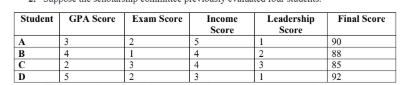

In [ ]:
import numpy as np
import pandas as pd
from numpy.linalg import lstsq, inv
from numpy.linalg import solve, inv

A = np.array([
    [3,2,5,1],
    [4,1,4,2],
    [2,3,4,3],
    [5,2,3,1]
],dtype=float)

b = np.array([90,88,85,92],dtype=float)

weights = solve(A,b)

criteria=["GPA","Exam","Income","Leadership"]

print("Recovered Weights")
for c,w in zip(criteria,weights):
    print(f"{c:12s}: {w:.4f}")

print("\nVerification")
print(A@weights)
print("Original:",b)

new_student=np.array([4,3,4,2],dtype=float)
score=new_student@weights
print("\nNew Student Features:",new_student)
print("Predicted Scholarship Score:",round(score,2))



Recovered Weights
GPA         : 9.8000
Exam        : 6.5333
Income      : 8.8000
Leadership  : 3.5333

Verification
[90. 88. 85. 92.]
Original: [90. 88. 85. 92.]

New Student Features: [4. 3. 4. 2.]
Predicted Scholarship Score: 101.07


# Example 2
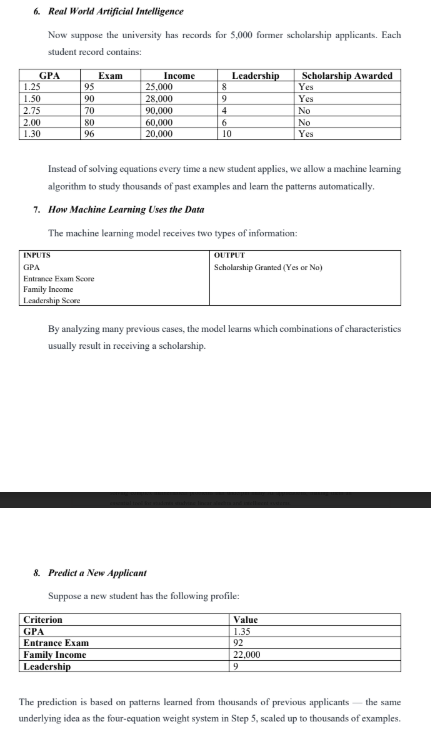

In [ ]:
import numpy as np
import pandas as pd
from numpy.linalg import lstsq, inv
from numpy.linalg import solve, inv

np.set_printoptions(precision=4, suppress=True)

data = {
    "GPA": [1.25, 1.50, 2.75, 2.00, 1.30],
    "Exam": [95, 90, 70, 80, 96],
    "Income": [25000, 28000, 90000, 60000, 20000],
    "Leadership": [8, 9, 4, 6, 10],
    "Scholarship": ["Yes", "Yes", "No", "No", "Yes"]
}

df = pd.DataFrame(data)

print("SCHOLARSHIP APPLICANT RECORDS")
print(df)

A = np.array([
    [1.25, 95, 25000, 8],
    [1.50, 90, 28000, 9],
    [2.75, 70, 90000, 4],
    [2.00, 80, 60000, 6],
    [1.30, 96, 20000, 10]
], dtype=float)

print("A = Matrix A")
print("Matrix A:")
print(A)

Scholarship_binary=[1.0 if val== "Yes" else 0.0 for val in data["Scholarship"]]

B = np.array(Scholarship_binary, dtype=float).reshape(-1,1)
b = np.array(Scholarship_binary, dtype=float)

print("B = Matrix B")
print("Matrix B:")
print(B)

weights, residuals, rank, s = np.linalg.lstsq(A, b, rcond=None)
weights = weights.flatten()

criteria = ["GPA", "Exam", "Income", "Leadership"]

print("\nMODEL WEIGHTS")
for criterion, weight in zip(criteria, weights):
    print(f"{criterion:12s}: {weight:.6f}")

print("\nVerification")
predictions = A @ weights
print("Raw scores:", predictions)
print("Original:",b)

new_applicant = pd.DataFrame ({
    "GPA": [1.35],
    "Exam": [92],
    "Income": [22000],
    "Leadership": [9]
})

print("\nNew Applicant Information")

new_student = np.array([1.35,92,22000,9])
prediction = new_student @ weights

print(new_applicant)
print("\nSCHOLARSHIP PREDICTION")

print(f"Prediction Score: {prediction:.4f}")
if prediction >= 0.5:
    print("Scholarship Awarded: YES")
else:
    print("Scholarship Awarded: NO")

SCHOLARSHIP APPLICANT RECORDS
    GPA  Exam  Income  Leadership Scholarship
0  1.25    95   25000           8         Yes
1  1.50    90   28000           9         Yes
2  2.75    70   90000           4          No
3  2.00    80   60000           6          No
4  1.30    96   20000          10         Yes
A = Matrix A
Matrix A:
[[    1.25    95.   25000.       8.  ]
 [    1.5     90.   28000.       9.  ]
 [    2.75    70.   90000.       4.  ]
 [    2.      80.   60000.       6.  ]
 [    1.3     96.   20000.      10.  ]]
B = Matrix B
Matrix B:
[[1.]
 [1.]
 [0.]
 [0.]
 [1.]]

MODEL WEIGHTS
GPA         : 4.657369
Exam        : 0.030077
Income      : -0.000143
Leadership  : -0.513638

Verification
Raw scores: [ 0.9891  1.0597 -0.0325  0.045   0.9409]
Original: [1. 1. 0. 0. 1.]

New Applicant Information
    GPA  Exam  Income  Leadership
0  1.35    92   22000           9

SCHOLARSHIP PREDICTION
Prediction Score: 1.2807
Scholarship Awarded: YES


# Linear Regression using the Normal Equation

# Example 1

In [ ]:
import numpy as np
import pandas as pd
from numpy.linalg import solve, inv

np.set_printoptions(precision=4,suppress=True)

data = {
    "Servers":[10,12,14,16,18,20,22,24,26,28,30,32,34,36,38],
    "CPU %":[50,48,52,55,54,60,58,61,63,64,55,66,67,65,68],
    "Energy (kWh)":[100,108,115,130,138,150,158,170,180,188,180,195,200,205,210]
}

df = pd.DataFrame(data)

print("DATA CENTER ENERGY DATA")
print(df)

X = np.column_stack((np.ones(len(data["Servers"])), data["Servers"], data["CPU %"]))
y = np.array(data["Energy (kWh)"],dtype=float).reshape(-1, 1)

XtX = X.T @ X
Xty = X.T @ y

print("\nX =")
print(X)

print("\nX^T X =")
print(XtX)

print("\nX^T y =")
print(Xty)

det = np.linalg.det(XtX)

print("\nDeterminant =", det)

if abs(det) < 1e-8:
    print("Matrix is singular.")
else:
    print("Matrix is invertible.")

XtX_inv = np.linalg.inv(XtX)
theta = XtX_inv @ Xty

print("\nInverse =")
print(np.round(XtX_inv, 6))

print("\nParameters")
print(theta)

print("\nLEAST-SQUARES MODEL")
print(
    f"y = {theta[0,0]:.3f} "
    f"+ {theta[1,0]:.3f}*Servers "
    f"+ {theta[2,0]:.3f}*CPU %")

new = np.array([1,27,59])
y_pred = theta.T @ new

print("\nNEW HOUR")
print("Servers =", 27)
print("CPU % =", 59)

print("\nPREDICTED ENERGY CONSUMPTION")
print(f"{y_pred} kWh")

DATA CENTER ENERGY DATA
    Servers  CPU %  Energy (kWh)
0        10     50           100
1        12     48           108
2        14     52           115
3        16     55           130
4        18     54           138
5        20     60           150
6        22     58           158
7        24     61           170
8        26     63           180
9        28     64           188
10       30     55           180
11       32     66           195
12       34     67           200
13       36     65           205
14       38     68           210

X =
[[ 1. 10. 50.]
 [ 1. 12. 48.]
 [ 1. 14. 52.]
 [ 1. 16. 55.]
 [ 1. 18. 54.]
 [ 1. 20. 60.]
 [ 1. 22. 58.]
 [ 1. 24. 61.]
 [ 1. 26. 63.]
 [ 1. 28. 64.]
 [ 1. 30. 55.]
 [ 1. 32. 66.]
 [ 1. 34. 67.]
 [ 1. 36. 65.]
 [ 1. 38. 68.]]

X^T X =
[[   15.   360.   886.]
 [  360.  9760. 21990.]
 [  886. 21990. 52918.]]

X^T y =
[[  2427.]
 [ 62770.]
 [146447.]]

Determinant = 1920739.999999919
Matrix is invertible.

Inverse =
[[17.139   0.2253 -0.3806]

# Example 1 Linear Regression

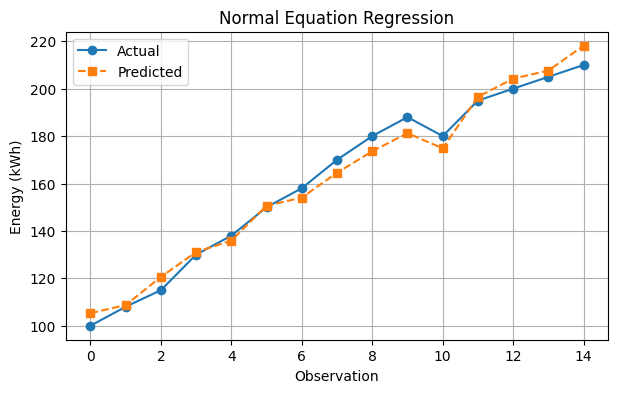

In [ ]:
import matplotlib.pyplot as plt

pred=(X@theta).flatten()

plt.figure(figsize=(7,4))
plt.plot(df["Energy (kWh)"], 'o-', label='Actual')
plt.plot(pred,'s--', label='Predicted')
plt.xlabel("Observation")
plt.ylabel("Energy (kWh)")
plt.title("Normal Equation Regression")
plt.legend()
plt.grid(True)
plt.show()


# Example 2

In [ ]:
import numpy as np
import pandas as pd
from numpy.linalg import solve, inv

np.set_printoptions(precision=4,suppress=True)

data = {
    "Servers":[10,20,30,40,15,25,35,45,12,28,33,50,18,22,38],
    "CPU %":[50,60,55,70,45,65,58,75,48,62,52,80,47,53,68],
    "Energy (kWh)":[100,150,180,220,115,165,200,245,108,175,190,265,122,148,210]
}

df = pd.DataFrame(data)

print("DATA CENTER ENERGY DATA")
print(df)

X = np.column_stack((np.ones(len(data["Servers"])), data["Servers"], data["CPU %"]))
y = np.array(data["Energy (kWh)"],dtype=float).reshape(-1, 1)

XtX = X.T @ X
Xty = X.T @ y

print("\nX =")
print(X)

print("\nX^T X =")
print(XtX)

print("\nX^T y =")
print(Xty)

det = np.linalg.det(XtX)

print("\nDeterminant =", det)

if abs(det) < 1e-8:
    print("Matrix is singular.")
else:
    print("Matrix is invertible.")

XtX_inv = np.linalg.inv(XtX)
theta = XtX_inv @ Xty

print("\nInverse =")
print(np.round(XtX_inv, 6))

print("\nParameters")
print(np.round(theta, 2))

print("\nLEAST-SQUARES MODEL")
print(
    f"y = {theta[0,0]:.2f} "
    f"+ {theta[1,0]:.2f}*Servers "
    f"+ {theta[2,0]:.2f}*CPU %")

new = np.array([1,27,59])
y_pred = theta.T @ new

print("\nNEW HOUR")
print("Servers =", 27)
print("CPU % =", 59)

print("\nPREDICTED ENERGY CONSUMPTION")
print(f"{y_pred[0]:.2f} kWh")

DATA CENTER ENERGY DATA
    Servers  CPU %  Energy (kWh)
0        10     50           100
1        20     60           150
2        30     55           180
3        40     70           220
4        15     45           115
5        25     65           165
6        35     58           200
7        45     75           245
8        12     48           108
9        28     62           175
10       33     52           190
11       50     80           265
12       18     47           122
13       22     53           148
14       38     68           210

X =
[[ 1. 10. 50.]
 [ 1. 20. 60.]
 [ 1. 30. 55.]
 [ 1. 40. 70.]
 [ 1. 15. 45.]
 [ 1. 25. 65.]
 [ 1. 35. 58.]
 [ 1. 45. 75.]
 [ 1. 12. 48.]
 [ 1. 28. 62.]
 [ 1. 33. 52.]
 [ 1. 50. 80.]
 [ 1. 18. 47.]
 [ 1. 22. 53.]
 [ 1. 38. 68.]]

X^T X =
[[   15.   421.   888.]
 [  421. 13869. 26479.]
 [  888. 26479. 54158.]]

X^T y =
[[  2593.]
 [ 81223.]
 [160147.]]

Determinant = 12605485.000000004
Matrix is invertible.

Inverse =
[[ 3.9649  0.0566 -0.0927

# Example 2 Linear Regression

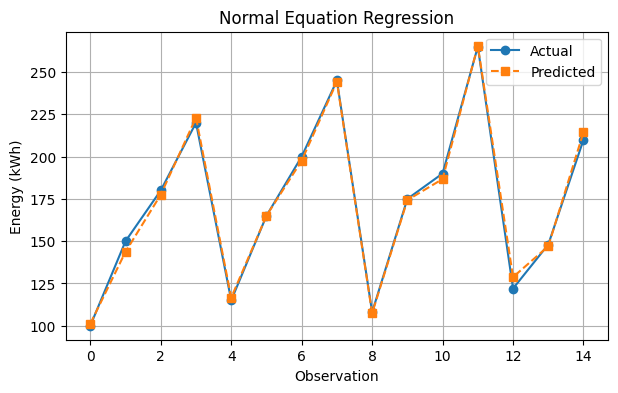

In [ ]:
import matplotlib.pyplot as plt

pred=(X@theta).flatten()

plt.figure(figsize=(7,4))
plt.plot(df["Energy (kWh)"], 'o-', label='Actual')
plt.plot(pred,'s--', label='Predicted')
plt.xlabel("Observation")
plt.ylabel("Energy (kWh)")
plt.title("Normal Equation Regression")
plt.legend()
plt.grid(True)
plt.show()
